# 03 — Cùng một cách chia, đổi thời điểm cảnh báo

**Câu hỏi:** Model HGB hiện có tốt lên khi chuyển từ 50% sang 60–75% không? Đây là đối chứng để biết thời điểm dự báo ảnh hưởng ra sao **trước** khi thay model. Các tập được cố định theo sinh viên qua mọi mốc; số dòng vẫn có thể khác do enrollment rút môn trước cutoff.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from NghienCuu_HCO_VNLS.code_dung_chung.thuc_nghiem import (
    GOC, NGHIEN_CUU, DATA, KET_QUA, HINH, CAC_MOC,
    tao_thu_muc, duong_dan, chia_nhom, nap_du_lieu, chon_dac_trung,
    tien_xu_ly, bo_sung_ty_le, bo_sung_cua_so_vle,
)
tao_thu_muc()
print('Dữ liệu nguồn:', DATA)
print('Kết quả riêng:', KET_QUA)

Dữ liệu nguồn: CLHT_GB_GITHUB\data
Kết quả riêng: CLHT_GB_GITHUB\NghienCuu_HCO_VNLS\ket_qua


In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from clht_code.evaluation import metric_table
from clht_code.models import make_pipeline, ModelConfig
from sklearn.ensemble import HistGradientBoostingClassifier

baseline = ModelConfig('HGB_160', HistGradientBoostingClassifier(max_iter=160, learning_rate=.08, max_leaf_nodes=15,
                              early_stopping=False, random_state=41))
rows = []
for cutoff in CAC_MOC:
    frame = nap_du_lieu(cutoff)
    features = chon_dac_trung(frame)
    train, valid = (frame[frame.split == value] for value in ('train', 'validation'))
    pipeline = make_pipeline(train[features], baseline)
    started = time.perf_counter()
    pipeline.fit(train[features], train.risk)
    p = pipeline.predict_proba(valid[features])[:, 1]
    values = metric_table(valid.risk, p)
    rows.append({'cutoff': cutoff, 'model': 'HGB_160', 'train_rows': len(train),
                 'validation_rows': len(valid), 'n_features': len(features),
                 'fit_and_predict_seconds': time.perf_counter()-started, **values})
result = pd.DataFrame(rows)
result.to_csv(KET_QUA/'hgb_theo_cutoff_validation.csv', index=False, encoding='utf-8-sig')
display(result[['cutoff','train_rows','validation_rows','accuracy','recall_risk','f1_risk','average_precision_risk','brier_score']].round(4))

Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

,cutoff,train_rows,validation_rows,accuracy,recall_risk,f1_risk,average_precision_risk,brier_score
0,0.50,17310,3638,0.8134,0.6439,0.7250,0.8505,0.1318
1,0.60,16845,3537,0.8425,0.6695,0.7560,0.8742,0.1137
2,0.65,16607,3479,0.8560,0.6913,0.7726,0.8870,0.1039
3,0.70,16458,3445,0.8644,0.6984,0.7817,0.8928,0.0990
4,0.75,16297,3415,0.8773,0.7044,0.7969,0.8986,0.0933


## 1. Vẽ đánh đổi: dự báo muộn dễ hơn nhưng hỗ trợ chậm hơn

Đường AP đo chất lượng xếp hạng nguy cơ; Accuracy phụ thuộc ngưỡng 0,5. Recall cho biết phần sinh viên nguy cơ được phát hiện. Đọc cả ba, không chọn cutoff chỉ vì Accuracy cao nhất.

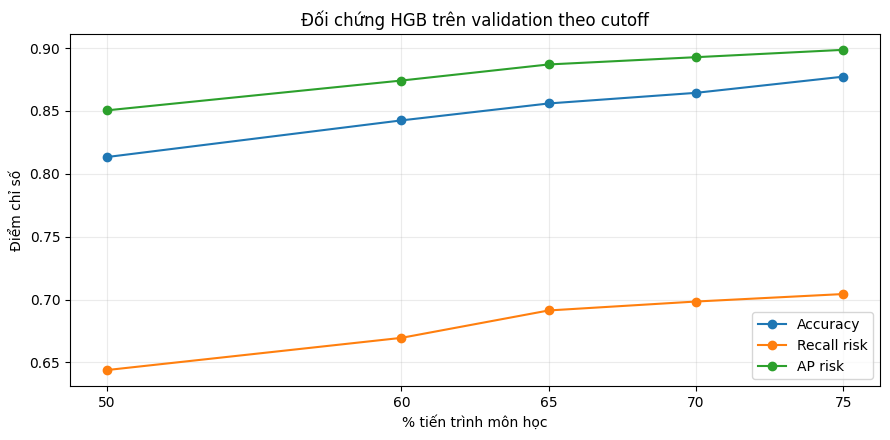

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for column, label in [('accuracy','Accuracy'),('recall_risk','Recall risk'),('average_precision_risk','AP risk')]:
    ax.plot(result.cutoff*100, result[column], marker='o', label=label)
ax.set(xlabel='% tiến trình môn học', ylabel='Điểm chỉ số', title='Đối chứng HGB trên validation theo cutoff')
ax.set_xticks(result.cutoff*100)
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(HINH/'hgb_theo_cutoff_validation.png', dpi=160)
plt.show()

**Giới hạn:** Mỗi mốc có tập enrollment hợp lệ khác nhau. Bảng này là so sánh triển khai tại từng thời điểm, không phải một thực nghiệm nhân quả trên chính xác cùng các dòng. Các thử nghiệm model mới cần tiếp tục giữ cùng split theo sinh viên và cùng quy tắc feature.

## Kết quả đọc nhanh — lần chạy 23/09/2026

Trên validation, HGB đạt Accuracy `0,8134` và AP `0,8505` tại 50%; ở 75%, Accuracy `0,8773`, AP `0,8986`. Recall risk tăng từ `0,6439` lên `0,7044`. **Không diễn giải đây là cải thiện nhờ đổi mốc duy nhất**, vì enrollment hợp lệ ở 50% và 75% không giống hệt nhau. Mốc 75% cũng chừa ít thời gian hỗ trợ hơn.